# ECE 3715 Mini-Project 1: Steps 1–3

Andrew Ore (Person 1): sample space, Monte Carlo simulations, conditional probability, Bayes, independence, and Figures 1–2.
This notebook completes **Person 1's Steps 1–3**. Steps 4–8 remain for the team.
**Team seed 1 is temporary.** Replace it with the actual team number and restart the kernel and run all cells before submission.

In [1]:
import time
from itertools import product
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from mp1lib import (
    bsc,
    packet_errors,
    tv_distance,
    attempts_until_clean
)

from scipy.stats import binom, poisson, geom

started = time.perf_counter()
SEED = 1  # TEMPORARY: replace with the actual team number.
rng = np.random.default_rng(SEED)

# Reserve a separate generator for every project step now.
rng_steps = [rng.spawn(1)[0] for _ in range(8)]
rng_step1 = rng_steps[0]
rng_tests = rng.spawn(1)[0]  # Tests do not consume any step's random stream.

p = 0.1
N = 10**6
print(f"Temporary team seed: {SEED}; Step 1 packets: {N:,}")

Temporary team seed: 1; Step 1 packets: 1,000,000


## Hand-checkable BSC test

BSC stands for binary symmetric channel. A 0 can flip to 1, and a 1 can flip
to 0, both with the same probability. At p=0 nothing flips. At p=1 every bit flips.
These tests check the function with both 0 and 1 as input bits.

In [ ]:
example = np.array([0, 1, 0, 1], dtype=np.uint8)
unchanged = bsc(example, 0.0, rng_tests)
flipped = bsc(example, 1.0, rng_tests)
assert np.array_equal(unchanged, [0, 1, 0, 1])
assert np.array_equal(flipped, [1, 0, 1, 0])
print("p=0:", unchanged, "  p=1:", flipped, "  Tests passed.")

## Hand-checkable packet_errors test

In [2]:
test_errors = packet_errors(10, 4, 0.0, rng_tests)
assert np.all(test_errors == 0)

test_errors = packet_errors(10, 4, 1.0, rng_tests)
assert np.all(test_errors == 4)

print("packet_errors tests passed.")

packet_errors tests passed.


## Hand-checkable tv-distance test

In [2]:
# Hand-checkable tests for total variation distance
assert tv_distance([0.2, 0.8], [0.2, 0.8]) == 0.0
assert tv_distance([1.0, 0.0], [0.0, 1.0]) == 1.0

print("tv_distance tests passed.")

tv_distance tests passed.


## Hand-checkable attempts_until_clean

In [ ]:
# If every transmission is clean, success always occurs on attempt 1.
test_attempts6 = attempts_until_clean(10, 1.0, rng_tests)

assert np.all(test_attempts6 == 1)

print("attempts_until_clean tests passed.")

## 1. Enumerate the sample space

Each of the four bit positions can be correct or wrong, giving $2^4=16$ patterns.
If a pattern has $k$ errors, we multiply the probabilities for its four
positions because the bit errors are independent:

$$P(\text{particular pattern})=p^k(1-p)^{4-k}.$$

For example,
$$P(0101)=0.9(0.1)(0.9)(0.1)=0.0081,$$
$$P(0000)=0.9^4=0.6561.$$

Each packet has exactly one of these patterns, so the patterns are mutually
exclusive. The list covers every possible outcome, so it is collectively
exhaustive and the probabilities must add to 1. At p=0.1, some patterns are
more likely than others.

In [3]:
patterns = np.array(list(product([0, 1], repeat=4)), dtype=np.uint8)
labels = ["".join(map(str, row)) for row in patterns]
k = patterns.sum(axis=1)
exact_patterns = p**k * (1-p)**(4-k)
enumeration = pd.DataFrame({
    "Pattern": labels, "Errors": k, "Exact probability": exact_patterns
})
print(enumeration.to_string(index=False, float_format=lambda x: f"{x:.6f}"))
print(f"Sum of the 16 exact probabilities = {exact_patterns.sum():.12f}")
assert np.isclose(exact_patterns.sum(), 1.0)

Pattern  Errors  Exact probability
   0000       0           0.656100
   0001       1           0.072900
   0010       1           0.072900
   0011       2           0.008100
   0100       1           0.072900
   0101       2           0.008100
   0110       2           0.008100
   0111       3           0.000900
   1000       1           0.072900
   1001       2           0.008100
   1010       2           0.008100
   1011       3           0.000900
   1100       2           0.008100
   1101       3           0.000900
   1110       3           0.000900
   1111       4           0.000100
Sum of the 16 exact probabilities = 1.000000000000


## 2. Exact event probabilities by hand

**A: at least one error among the first two bits.** The first two positions
can be 01, 10, or 11. The last two positions can be either value.
$$P(A)=0.9(0.1)+0.1(0.9)+0.1(0.1)=0.19.$$
We can also subtract the chance that the first two bits are both correct:
$$P(A)=1-(1-p)^2=1-0.9^2=0.19.$$

**B: exactly two errors in the four-bit packet.** The six patterns are
0011, 0101, 0110, 1001, 1010, and 1100. Each has probability 0.0081.
$$P(B)=6p^2(1-p)^2=6(0.1)^2(0.9)^2=0.0486.$$

**C: the fourth bit is in error.** The other positions can be either value.
$$P(C)=p=0.1.$$

## Exact overlaps

**A and B:** 0011 has no error in the first two positions, so it does not
meet A. Removing it from B's six patterns leaves five.
$$P(A\cap B)=5p^2(1-p)^2=5(0.0081)=0.0405.$$

**A and C:** A uses only the first two bits, and C uses only the fourth bit.
Since the bit errors are independent, A and C are independent too.
$$P(A\cap C)=P(A)P(C)=0.19(0.1)=0.0190.$$

**B and C:** the fourth bit must be wrong. Exactly one of the first three
bits must also be wrong to give two errors in total. The three patterns are 0011, 0101, and 1001.
$$P(B\cap C)=3p^2(1-p)^2=3(0.0081)=0.0243.$$

**A, B, and C:** only 0101 and 1001 meet all three conditions.
$$P(A\cap B\cap C)=2p^2(1-p)^2=2(0.0081)=0.0162.$$

## Inclusion–exclusion

Add the three events, subtract the pairwise overlaps, then add the triple
overlap back. A pattern in all three events was added three times and
subtracted three times, so adding it back makes sure it is counted once.

$$\begin{aligned}
P(A\cup B\cup C)={}&P(A)+P(B)+P(C)\\
  &-P(A\cap B)-P(A\cap C)-P(B\cap C)\\
  &+P(A\cap B\cap C)\\
={}&0.19+0.0486+0.1-0.0405-0.0190-0.0243+0.0162\\
={}&0.2710.
\end{aligned}$$

## 3. Simulate one million packets

Each row is one packet and each column is one bit position. We send packets
containing only zeros, so a received 1 means that position flipped. This lets
us read the error pattern directly from the received packet. The BSC has the
same flip probability for 0 and 1, and the test above checks both inputs.

NumPy generates all the bit flips together. We then create true/false arrays
for A, B, and C. Taking the mean of one of these arrays gives the fraction of packets
where that event happened.
Python column numbering starts at zero, so column 3 is the fourth bit.

In [4]:
transmitted = np.zeros((N, 4), dtype=np.uint8)
received = bsc(transmitted, p, rng_step1)
errors = received != transmitted

A = errors[:, :2].any(axis=1)
B = errors.sum(axis=1) == 2
C = errors[:, 3]

# & means AND between true/false arrays; | means OR.
event_masks = {
    "A": A, "B": B, "C": C,
    "A & B": A & B, "A & C": A & C, "B & C": B & C,
    "A & B & C": A & B & C,
    "A | B | C": A | B | C,
}

# Convert patterns to integer labels 0 through 15, keeping bit 1 leftmost.
pattern_ids = errors.astype(np.uint8) @ np.array([8, 4, 2, 1])
observed_counts = np.bincount(pattern_ids, minlength=16)
empirical_patterns = observed_counts / N
assert observed_counts.sum() == N

## 4. Numerical comparisons and standard errors

For an event with true probability $\theta$, its Monte Carlo estimate is
$\hat\theta=(\text{qualifying packet count})/N$. Its standard error is
$$SE(\hat\theta)=\sqrt{\frac{\theta(1-\theta)}{N}}.$$
Here $\theta$ is the event probability, not necessarily the bit error
probability p. For A, $SE=\sqrt{0.19(0.81)/10^6}\approx0.0003923$.
Compare $|\hat\theta-\theta|$ with $3SE$. Small differences are expected because the simulation uses random samples.
The three-SE check helps judge whether a difference is reasonable, although
an occasional run can fall outside this range.

In [5]:
exact = {
    "A": 1-(1-p)**2,
    "B": 6*p**2*(1-p)**2,
    "C": p,
    "A & B": 5*p**2*(1-p)**2,
    "A & C": (1-(1-p)**2)*p,
    "B & C": 3*p**2*(1-p)**2,
    "A & B & C": 2*p**2*(1-p)**2,
}
exact["A | B | C"] = (
    exact["A"] + exact["B"] + exact["C"]
    - exact["A & B"] - exact["A & C"] - exact["B & C"]
    + exact["A & B & C"]
)

rows = []
for name, theta in exact.items():
    count = int(event_masks[name].sum())
    estimate = count / N
    se = np.sqrt(theta*(1-theta)/N)
    difference = estimate - theta
    rows.append({
        "Event": name, "Count": count, "Exact": theta,
        "Estimated": estimate, "Difference": difference,
        "SE": se, "Abs difference / SE": abs(difference)/se,
        "Within 3 SE": bool(abs(difference) <= 3*se),
    })
comparison = pd.DataFrame(rows)
print("Required seven event and overlap comparisons:")
print(comparison.iloc[:7].to_string(index=False, float_format=lambda x: f"{x:.6f}"))
print("\nAdditional union comparison:")
print(comparison.iloc[7:].to_string(index=False, float_format=lambda x: f"{x:.6f}"))

inclusion_exclusion_empirical = (
    A.mean() + B.mean() + C.mean()
    - (A & B).mean() - (A & C).mean() - (B & C).mean()
    + (A & B & C).mean()
)
direct_union_empirical = (A | B | C).mean()
print(f"\nExact union: {exact['A | B | C']:.6f}")
print(f"Empirical union, inclusion–exclusion: {inclusion_exclusion_empirical:.6f}")
print(f"Empirical union, direct OR count:     {direct_union_empirical:.6f}")
print(f"Difference between empirical methods: "
      f"{abs(inclusion_exclusion_empirical-direct_union_empirical):.3e}")
assert np.isclose(inclusion_exclusion_empirical, direct_union_empirical)
assert np.allclose([exact['A'], exact['B'], exact['C'], exact['A | B | C']],
                   [0.19, 0.0486, 0.1, 0.2710])

print(f"\nAll eight event comparisons within three SE: "
      f"{comparison['Within 3 SE'].all()}")
if not comparison['Within 3 SE'].all():
    print("Report the failing comparisons; do not change the seed to hide them.")

Required seven event and overlap comparisons:
    Event  Count    Exact  Estimated  Difference       SE  Abs difference / SE  Within 3 SE
        A 190599 0.190000   0.190599    0.000599 0.000392             1.526889         True
        B  48737 0.048600   0.048737    0.000137 0.000215             0.637119         True
        C 100071 0.100000   0.100071    0.000071 0.000300             0.236667         True
    A & B  40620 0.040500   0.040620    0.000120 0.000197             0.608739         True
    A & C  19118 0.019000   0.019118    0.000118 0.000137             0.864312         True
    B & C  24430 0.024300   0.024430    0.000130 0.000154             0.844271         True
A & B & C  16313 0.016200   0.016313    0.000113 0.000126             0.895092         True

Additional union comparison:
    Event  Count    Exact  Estimated  Difference       SE  Abs difference / SE  Within 3 SE
A | B | C 271552 0.271000   0.271552    0.000552 0.000444             1.241912         True

Exa

## 5. Figure 1: exact pattern probabilities and simulated estimates

This figure shows all 16 exact probabilities as bars and the
simulated frequencies as markers. The printed outcome table also reports
numerical differences and standard errors for each pattern.

Pattern  Count    Exact  Estimated  Difference       SE  Abs difference / SE  Within 3 SE
   0000 655609 0.656100   0.655609   -0.000491 0.000475             1.033666         True
   0001  72836 0.072900   0.072836   -0.000064 0.000260             0.246180         True
   0010  72839 0.072900   0.072839   -0.000061 0.000260             0.234640         True
   0011   8117 0.008100   0.008117    0.000017 0.000090             0.189659         True
   0100  73286 0.072900   0.073286    0.000386 0.000260             1.484774         True
   0101   8068 0.008100   0.008068   -0.000032 0.000090             0.357004         True
   0110   8150 0.008100   0.008150    0.000050 0.000090             0.557819         True
   0111    908 0.000900   0.000908    0.000008 0.000030             0.266787         True
   1000  72996 0.072900   0.072996    0.000096 0.000260             0.369270         True
   1001   8245 0.008100   0.008245    0.000145 0.000090             1.617676         True
   1010   

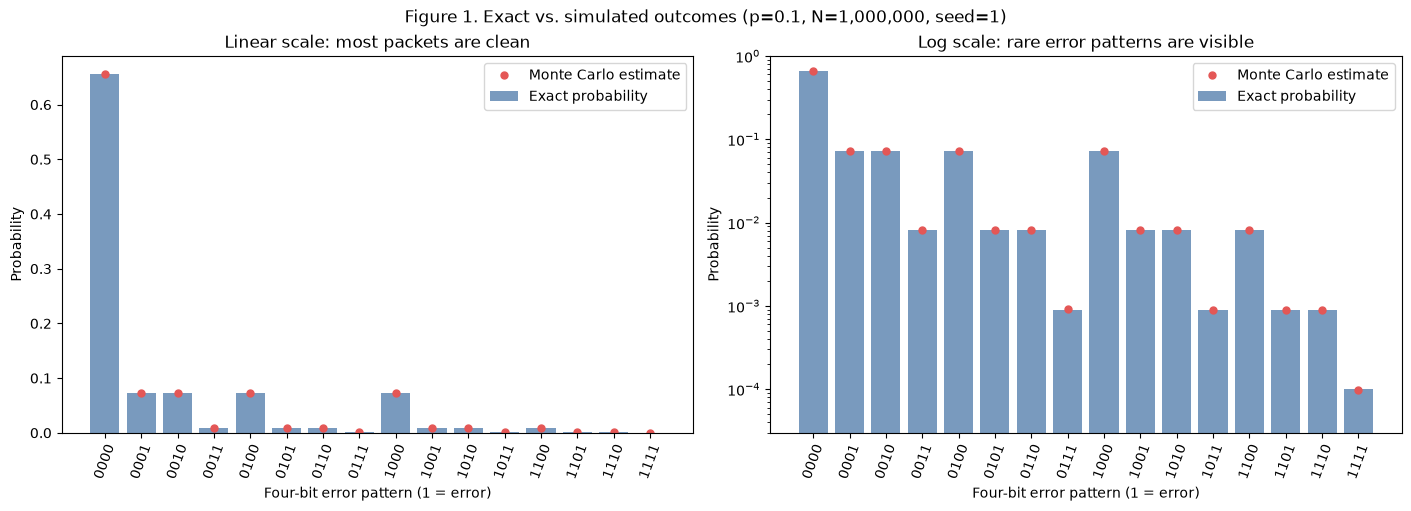

In [6]:
pattern_se = np.sqrt(exact_patterns*(1-exact_patterns)/N)
pattern_difference = empirical_patterns - exact_patterns
outcome_comparison = pd.DataFrame({
    "Pattern": labels, "Count": observed_counts,
    "Exact": exact_patterns, "Estimated": empirical_patterns,
    "Difference": pattern_difference, "SE": pattern_se,
    "Abs difference / SE": np.abs(pattern_difference)/pattern_se,
    "Within 3 SE": np.abs(pattern_difference) <= 3*pattern_se,
})
print(outcome_comparison.to_string(index=False, float_format=lambda x: f"{x:.6f}"))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
positions = np.arange(16)
for ax in axes:
    ax.bar(positions, exact_patterns, label="Exact probability", color="#4c78a8", alpha=0.75)
    ax.plot(positions, empirical_patterns, "o", label="Monte Carlo estimate",
            color="#e45756", markersize=5)
    ax.set_xticks(positions, labels, rotation=70)
    ax.set_xlabel("Four-bit error pattern (1 = error)")
    ax.set_ylabel("Probability")
    ax.legend()
axes[0].set_title("Linear scale: most packets are clean")
axes[1].set_yscale("log")
axes[1].set_ylim(0.00003, 1)
axes[1].set_title("Log scale: rare error patterns are visible")
fig.suptitle(f"Figure 1. Exact vs. simulated outcomes (p={p}, N={N:,}, seed={SEED})")
plt.show()

## Figure 1 interpretation

The clean pattern 0000 has the highest probability because every bit is more
likely to be correct than wrong. Changing a correct position to an error
changes one factor from 0.9 to 0.1. This makes that particular pattern nine
times less likely for each additional error. Patterns with the same error
count have equal exact probabilities. Their simulated frequencies vary slightly because we used a limited number
of random trials. The panel with a logarithmic axis makes the rare patterns easier to see.
Equal vertical spacing on that axis means equal ratios rather than equal
probability differences. The tables show the differences and standard errors.

The paragraph below includes numbers from the current run. Rerun from the top after changing the seed to update it.

In [7]:
union_row = comparison.iloc[-1]
worst_event = comparison.loc[comparison["Abs difference / SE"].idxmax()]
worst_pattern = outcome_comparison.loc[outcome_comparison["Abs difference / SE"].idxmax()]
event_status = "All eight" if comparison["Within 3 SE"].all() else "Not all eight"
pattern_status = "All 16" if outcome_comparison["Within 3 SE"].all() else "Not all 16"
interpretation = (
    f"The clean pattern 0000 is the most likely. Its exact probability is **0.6561**, "
    f"and its simulated estimate is **{empirical_patterns[0]:.6f}**, "
    f"a difference of **{pattern_difference[0]:+.6f}** with SE "
    f"**{pattern_se[0]:.6f}**. Each particular pattern becomes less likely as "
    f"its error count increases. The right panel uses a logarithmic y axis "
    f"to make rare outcomes easier to see. Equal vertical spacing represents equal "
    f"ratios rather than equal probability differences. {pattern_status} "
    f"outcome comparisons are within three SE. The largest difference is "
    f"**{worst_pattern['Abs difference / SE']:.3f} SE** for pattern "
    f"**{worst_pattern['Pattern']}**. {event_status} event and union comparisons "
    f"are within three SE. The largest event difference is "
    f"**{worst_event['Abs difference / SE']:.3f} SE** for "
    f"**{worst_event['Event']}**. The union estimate is "
    f"**{union_row['Estimated']:.6f}** compared with theory **0.271000**, "
    f"an absolute difference of **{abs(union_row['Difference']):.6f}**, "
    f"or **{union_row['Abs difference / SE']:.3f} SE**, with SE "
    f"**{union_row['SE']:.6f}**. Direct counting and empirical "
    f"inclusion–exclusion agree to within "
    f"**{abs(inclusion_exclusion_empirical-direct_union_empirical):.3e}**."
)
display(Markdown(interpretation))
runtime_seconds = time.perf_counter() - started
print(f"Step 1 runtime: {runtime_seconds:.3f} seconds")

The clean pattern 0000 is the most likely. Its exact probability is **0.6561**, and its simulated estimate is **0.655609**, a difference of **-0.000491** with SE **0.000475**. Each particular pattern becomes less likely as its error count increases. The right panel uses a logarithmic y axis to make rare outcomes easier to see. Equal vertical spacing represents equal ratios rather than equal probability differences. All 16 outcome comparisons are within three SE. The largest difference is **1.618 SE** for pattern **1001**. All eight event and union comparisons are within three SE. The largest event difference is **1.527 SE** for **A**. The union estimate is **0.271552** compared with theory **0.271000**, an absolute difference of **0.000552**, or **1.242 SE**, with SE **0.000444**. Direct counting and empirical inclusion–exclusion agree to within **0.000e+00**.

Step 1 runtime: 177.146 seconds


# Step 2: Conditional probability and Bayes

Let $E$ mean a bit is actually wrong and $F$ mean the circuit flags it.
The detector probabilities and the prior error probability are
$$P(F\mid E)=0.95,\qquad P(F\mid E^c)=0.02,\qquad P(E)=p.$$
Therefore $P(E^c)=1-p$. The detector's sensitivity is 95%, meaning it flags 95% of wrong bits.
We still need to find the probability that a flagged bit is actually wrong.

## Derive the posterior

The joint probability of a flag and an actual error is
$$P(F\cap E)=P(F\mid E)P(E)=0.95p.$$
A flag can come from a wrong bit or a correct bit. A bit cannot be both,
and these are the only two possibilities. The law of total probability gives
$$\begin{aligned}
P(F)&=P(F\mid E)P(E)+P(F\mid E^c)P(E^c)\\
    &=0.95p+0.02(1-p).
\end{aligned}$$
Using conditional probability gives Bayes' posterior, the probability
that a bit is wrong given that it was flagged:
$$\begin{aligned}
P(E\mid F)&=\frac{P(E\cap F)}{P(F)}\\
          &=\frac{P(F\mid E)P(E)}{P(F\mid E)P(E)+P(F\mid E^c)P(E^c)}\\
          &=\boxed{\frac{0.95p}{0.95p+0.02(1-p)}}.
\end{aligned}$$

This is flags for real errors divided by all flags. For example, among
100,000 bits at $p=0.001$, we expect 100 wrong bits and 99,900 correct bits.
We then expect 95 flags for real errors and 1,998 false alarms, giving
$95/(95+1998)=0.045389\ldots$.

In [8]:
sensitivity2 = 0.95
false_alarm_rate2 = 0.02
p_cases2 = np.array([0.1, 0.01, 0.001])
posterior_cases2 = sensitivity2*p_cases2 / (
    sensitivity2*p_cases2 + false_alarm_rate2*(1-p_cases2)
)
bayes_cases2 = pd.DataFrame({
    "Prior p": p_cases2,
    "P(error | flag)": posterior_cases2,
    "Posterior percent": 100*posterior_cases2,
})
print(bayes_cases2.to_string(index=False, float_format=lambda x: f"{x:.6f}"))

 Prior p  P(error | flag)  Posterior percent
0.100000         0.840708          84.070796
0.010000         0.324232          32.423208
0.001000         0.045389           4.538939


## Find the 50% crossover analytically

Set the posterior to one half and solve for p. Keep the full value for
the simulation:
$$\begin{aligned}
\frac{0.95p}{0.95p+0.02(1-p)}&=\frac12\\
2(0.95p)&=0.95p+0.02(1-p)\\
0.95p&=0.02(1-p)\\
0.95p&=0.02-0.02p\\
0.97p&=0.02\\
p_*&=\frac{0.02}{0.97}=0.0206185567\ldots.
\end{aligned}$$
To three significant figures, report $\boxed{p_*=0.0206}$, or 2.06%.
At the crossover, a flag is equally likely to be a real error or a false alarm.
The total probability of a flag is
$$P(F)=0.95p_*+0.02(1-p_*)=0.0391752577\ldots,$$
so only about 3.92% of transmitted bits get flagged and enter the posterior
calculation.

In [9]:
crossover_p2 = false_alarm_rate2 / (sensitivity2 + false_alarm_rate2)
crossover_posterior2 = sensitivity2*crossover_p2 / (
    sensitivity2*crossover_p2 + false_alarm_rate2*(1-crossover_p2)
)
flag_probability2 = (sensitivity2*crossover_p2
                     + false_alarm_rate2*(1-crossover_p2))
print(f"Crossover p, full precision: {crossover_p2:.12f}")
print(f"Crossover p, three significant figures: {crossover_p2:.3g}")
print(f"Exact posterior at the crossover: {crossover_posterior2:.6f}")
print(f"Exact probability of getting a flag: {flag_probability2:.9f}")
assert np.isclose(crossover_posterior2, 0.5)

Crossover p, full precision: 0.020618556701
Crossover p, three significant figures: 0.0206
Exact posterior at the crossover: 0.500000
Exact probability of getting a flag: 0.039175258


## Verify the crossover with ten million bits

Use the separate Step 2 random generator. The BSC function simulates which
bits are wrong. Another random draw for each bit simulates the flagging
circuit. A wrong bit is flagged with probability 0.95, and a correct bit is
flagged with probability 0.02.

The posterior estimate uses only the flagged group:
$$\hat r=\frac{N_{F\cap E}}{N_F},\qquad
  N_F=N_{F\cap E}+N_{F\cap E^c}.$$
Once the flag count $N_F$ is known, each flagged bit is an independent
Bernoulli trial with two outcomes, actually wrong or actually correct. The estimated standard error of the ratio is
$$\widehat{SE}(\hat r)=\sqrt{\frac{\hat r(1-\hat r)}{N_F}}.$$
The denominator here is the actual flag count, not ten million. We compare the estimate with the theoretical posterior of 0.5 and report
the difference, the standard error, and how many standard errors apart they are.

In [10]:
rng_step2 = rng_steps[1]
N_bits2 = 10**7
actual_errors2 = bsc(np.zeros(N_bits2, dtype=np.uint8),
                     crossover_p2, rng_step2).astype(bool)
flag_probabilities2 = np.where(actual_errors2, sensitivity2, false_alarm_rate2)
flags2 = rng_step2.random(N_bits2) < flag_probabilities2
del flag_probabilities2

n_actual_errors2 = int(actual_errors2.sum())
n_flags2 = int(flags2.sum())
n_true_flags2 = int((flags2 & actual_errors2).sum())
n_false_flags2 = int((flags2 & ~actual_errors2).sum())
assert n_flags2 == n_true_flags2 + n_false_flags2
assert n_flags2 > 0

posterior_estimate2 = n_true_flags2 / n_flags2
posterior_se2 = np.sqrt(posterior_estimate2*(1-posterior_estimate2)/n_flags2)
posterior_difference2 = posterior_estimate2 - crossover_posterior2
posterior_z2 = abs(posterior_difference2)/posterior_se2
counts2 = pd.DataFrame({
    "Quantity": ["Transmitted bits", "Actually wrong bits", "Real-error flags",
                 "False alarms", "All flags"],
    "Count": [N_bits2, n_actual_errors2, n_true_flags2, n_false_flags2, n_flags2],
})
print(counts2.to_string(index=False))
print(f"Actual flagged fraction: {n_flags2/N_bits2:.9f}")
print(f"Expected flagged fraction: {flag_probability2:.9f}")
comparison2 = pd.DataFrame([{
    "Exact posterior": crossover_posterior2,
    "Estimated posterior": posterior_estimate2,
    "Difference": posterior_difference2,
    "Ratio SE": posterior_se2,
    "Abs difference / SE": posterior_z2,
    "Within 3 SE": bool(posterior_z2 <= 3),
}])
print("\nCrossover posterior comparison:")
print(comparison2.to_string(index=False, float_format=lambda x: f"{x:.9f}"))
del actual_errors2, flags2

           Quantity    Count
   Transmitted bits 10000000
Actually wrong bits   207091
   Real-error flags   196765
       False alarms   195712
          All flags   392477
Actual flagged fraction: 0.039247700
Expected flagged fraction: 0.039175258

Crossover posterior comparison:
 Exact posterior  Estimated posterior  Difference    Ratio SE  Abs difference / SE  Within 3 SE
     0.500000000          0.501341480 0.001341480 0.000798107          1.680826276         True


## Figure 2: posterior versus prior

Use 200 prior values spaced evenly on a logarithmic scale from 10^-4 to
10^-1. Mark the exact crossover and add the simulated estimate with an error
bar showing plus or minus one standard error. The error bar is small because the simulation is large.

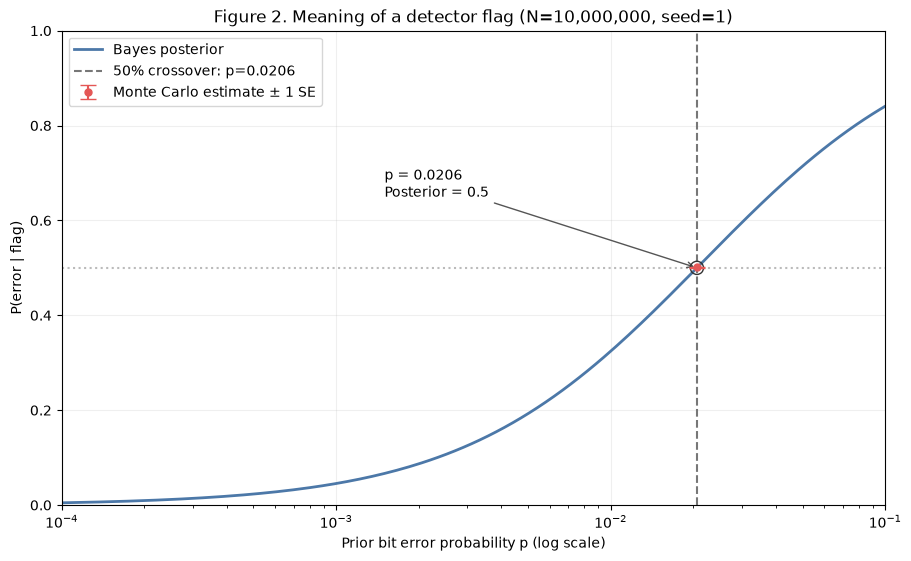

In [11]:
p_grid2 = np.logspace(-4, -1, 200)
posterior_grid2 = sensitivity2*p_grid2 / (
    sensitivity2*p_grid2 + false_alarm_rate2*(1-p_grid2)
)
assert len(p_grid2) == 200
fig2, ax2 = plt.subplots(figsize=(9, 5.5), constrained_layout=True)
ax2.plot(p_grid2, posterior_grid2, color="#4c78a8", linewidth=2,
         label="Bayes posterior")
ax2.axvline(crossover_p2, color="#777777", linestyle="--",
            label=f"50% crossover: p={crossover_p2:.3g}")
ax2.axhline(0.5, color="#bbbbbb", linestyle=":")
ax2.scatter([crossover_p2], [0.5], s=90, facecolors="none",
            edgecolors="#333333", zorder=4)
ax2.errorbar([crossover_p2], [posterior_estimate2], yerr=[posterior_se2],
            fmt="o", color="#e45756", capsize=6, markersize=5,
            label="Monte Carlo estimate ± 1 SE", zorder=5)
ax2.annotate(f"p = {crossover_p2:.3g}\nPosterior = 0.5",
             xy=(crossover_p2, 0.5), xytext=(0.0015, 0.65),
             arrowprops={"arrowstyle": "->", "color": "#555555"})
ax2.set_xscale("log")
ax2.set_xlim(1e-4, 1e-1)
ax2.set_ylim(0, 1)
ax2.set_xlabel("Prior bit error probability p (log scale)")
ax2.set_ylabel("P(error | flag)")
ax2.set_title(f"Figure 2. Meaning of a detector flag (N={N_bits2:,}, seed={SEED})")
ax2.grid(alpha=0.2)
ax2.legend(loc="upper left")
plt.show()

## Figure 2 interpretation

A flag is more likely to mean a real error as the prior error probability
increases. When errors are rare, there are so many correct bits that false
alarms make up most of the flagged group. At p=0.001, a
flag indicates a real error only about 4.54% of the time, despite the 95%
sensitivity. At p=0.1 that posterior rises to about 84.07%. The curve crosses
0.5 at p=0.0206. The Monte Carlo point and its error bar let us check the posterior at the
crossover. The difference is too small to see clearly on this graph, so the
table and the paragraph below report its value and standard error.

## Explanation for a manager

On a link where only 0.1% of bits are wrong, about 4.54% of the circuit's flags
indicate real errors. The circuit detects 95% of wrong bits, but its 2%
false alarm rate applies to a much larger number of correct bits, so false
alarms greatly outnumber flags for real errors. The meaning of a flag therefore
depends on the link's error rate, not just the detector's sensitivity.

In [12]:
display(Markdown(
    f"At the crossover **p = {crossover_p2:.12f}**, the simulation generated "
    f"**{n_flags2:,} flags** out of **{N_bits2:,} bits**, including "
    f"**{n_true_flags2:,} flags for real errors** and **{n_false_flags2:,} false alarms**. "
    f"The posterior estimate is **{posterior_estimate2:.9f}**, compared with "
    f"the exact value **0.500000000**. The estimate minus theory is "
    f"**{posterior_difference2:+.9f}**, with an estimated ratio standard error "
    f"of **{posterior_se2:.9f}**. The difference is **{posterior_z2:.3f} SE**. "
    f"This {'is' if posterior_z2 <= 3 else 'is not'} within three SE."
))
checkpoint_runtime = time.perf_counter() - started
print(f"Steps 1–2 checkpoint runtime: {checkpoint_runtime:.3f} seconds")

At the crossover **p = 0.020618556701**, the simulation generated **392,477 flags** out of **10,000,000 bits**, including **196,765 flags for real errors** and **195,712 false alarms**. The posterior estimate is **0.501341480**, compared with the exact value **0.500000000**. The estimate minus theory is **+0.001341480**, with an estimated ratio standard error of **0.000798107**. The difference is **1.681 SE**. This is within three SE.

Steps 1–2 checkpoint runtime: 178.309 seconds


# Step 3: Independence

## Part 1: pairwise independence does not imply mutual independence

Two independent fair coins have four equally likely outcomes:

| Outcome | $E_1$: first heads | $E_2$: second heads | $E_3$: coins match |
|---|---|---|---|
| HH | Yes | Yes | Yes |
| HT | Yes | No | No |
| TH | No | Yes | No |
| TT | No | No | Yes |

Each event occurs in two outcomes, so $P(E_1)=P(E_2)=P(E_3)=2/4=1/2$.
For each pair of events, HH is the only outcome where both happen. This gives
$$\begin{aligned}
P(E_1\cap E_2)&=1/4=(1/2)(1/2)=P(E_1)P(E_2),\\
P(E_1\cap E_3)&=1/4=(1/2)(1/2)=P(E_1)P(E_3),\\
P(E_2\cap E_3)&=1/4=(1/2)(1/2)=P(E_2)P(E_3).
\end{aligned}$$
Every pair passes, proving **pairwise independence**. For all three,
$$P(E_1\cap E_2\cap E_3)=P(\{HH\})=1/4,$$
while
$$P(E_1)P(E_2)P(E_3)=(1/2)^3=1/8.$$
The difference is $1/4-1/8=1/8$, so **mutual independence fails**.
Another way to see this is that knowing both coins are heads means
they must match:
$P(E_3\mid E_1\cap E_2)=1$, compared with $P(E_3)=1/2$.

### Standard errors for the numerical comparisons

Simulate $10^6$ coin pairs. For a set of event indices $S$, let
$I_{ik}=1$ if event $E_i$ happens in trial $k$, and zero otherwise.
Let $\hat p_i=N^{-1}\sum_k I_{ik}$, $J_k=\prod_{i\in S}I_{ik}$,
$\hat j=N^{-1}\sum_k J_k$, and $\hat m=\prod_{i\in S}\hat p_i$.
The table compares the estimated joint probability with the product
of the estimated event probabilities:
$\hat D=\hat j-\hat m$. These estimates use the same coin trials, so their
estimation errors are related. A first-order expansion gives
$$\begin{aligned}
\hat m-m&\approx\sum_{i\in S}\left(\prod_{\ell\in S,\ell\ne i}p_\ell\right)(\hat p_i-p_i),\\
\hat D-D&\approx N^{-1}\sum_k h_k,\\
h_k&=(J_k-\hat j)-\sum_{i\in S}\left(\prod_{\ell\in S,\ell\ne i}\hat p_\ell\right)(I_{ik}-\hat p_i),\\
\widehat{SE}(\hat D)&=\frac{s_h}{\sqrt N},\qquad
s_h^2=\frac{1}{N-1}\sum_k(h_k-\bar h)^2.
\end{aligned}$$
This includes the effect of using the same samples. The joint estimate
also has its own
binomial SE $\sqrt{j(1-j)/N}$, using the known exact $j=1/4$.
The table shows how far the joint estimates are from theory and how far
they are from the products. Theory gives a zero gap for each pair and a
gap of 0.125 for all three events together.

In [13]:
rng_step3 = rng_steps[2]
N_coins3 = 10**6
coins3 = rng_step3.integers(0, 2, size=(N_coins3, 2), dtype=np.uint8)
events3 = np.column_stack((coins3[:, 0] == 1,
                           coins3[:, 1] == 1,
                           coins3[:, 0] == coins3[:, 1])).astype(float)
event_rates3 = events3.mean(axis=0)
coin_rows3 = []
for label3, indices3 in [("E1 & E2", (0, 1)), ("E1 & E3", (0, 2)),
                         ("E2 & E3", (1, 2)), ("E1 & E2 & E3", (0, 1, 2))]:
    joint_indicator3 = np.prod(events3[:, indices3], axis=1)
    joint_estimate3 = joint_indicator3.mean()
    product_estimate3 = np.prod(event_rates3[list(indices3)])
    joint_exact3 = 0.25
    product_exact3 = 0.5**len(indices3)
    gap_exact3 = joint_exact3 - product_exact3
    gap_estimate3 = joint_estimate3 - product_estimate3
    gap_influence3 = joint_indicator3 - joint_estimate3
    for index3 in indices3:
        other_product3 = np.prod([event_rates3[i] for i in indices3 if i != index3])
        gap_influence3 -= other_product3*(events3[:, index3]-event_rates3[index3])
    gap_se3 = gap_influence3.std(ddof=1)/np.sqrt(N_coins3)
    joint_se3 = np.sqrt(joint_exact3*(1-joint_exact3)/N_coins3)
    coin_rows3.append({
        "Events": label3, "Exact product": product_exact3,
        "Empirical product": product_estimate3, "Exact joint": joint_exact3,
        "Empirical joint": joint_estimate3,
        "Joint - theory": joint_estimate3-joint_exact3, "Joint SE": joint_se3,
        "Joint - product": gap_estimate3, "Gap SE": gap_se3,
        "Gap - exact gap": gap_estimate3-gap_exact3,
        "Gap discrepancy / SE": abs(gap_estimate3-gap_exact3)/gap_se3,
    })
coin_table3 = pd.DataFrame(coin_rows3)
assert N_coins3 == 10**6
assert np.isclose(coin_table3.iloc[-1]["Exact joint"]
                  - coin_table3.iloc[-1]["Exact product"], 0.125)
print("Table 3A. Coin independence checks (N = 1,000,000)")
print("Empirical event probabilities:",
      ", ".join(f"P(E{i+1})={v:.9f}" for i, v in enumerate(event_rates3)))
print(coin_table3.to_string(index=False, float_format=lambda x: f"{x:.9f}"))

Table 3A. Coin independence checks (N = 1,000,000)
Empirical event probabilities: P(E1)=0.499779000, P(E2)=0.500838000, P(E3)=0.500069000
      Events  Exact product  Empirical product  Exact joint  Empirical joint  Joint - theory    Joint SE  Joint - product      Gap SE  Gap - exact gap  Gap discrepancy / SE
     E1 & E2    0.250000000        0.250308315  0.250000000      0.250343000     0.000343000 0.000433013      0.000034685 0.000250000      0.000034685           0.138740932
     E1 & E3    0.250000000        0.249923985  0.250000000      0.250343000     0.000343000 0.000433013      0.000419015 0.000250000      0.000419015           1.676062692
     E2 & E3    0.250000000        0.250453558  0.250000000      0.250343000     0.000343000 0.000433013     -0.000110558 0.000250000     -0.000110558           0.442231736
E1 & E2 & E3    0.125000000        0.125171429  0.250000000      0.250343000     0.000343000 0.000433013      0.125171571 0.000216407      0.000171571           0.7928170

In [14]:
pair_worst3 = coin_table3.iloc[:3]["Gap discrepancy / SE"].max()
triple_row3 = coin_table3.iloc[-1]
joint_worst3 = (abs(coin_table3["Joint - theory"])/coin_table3["Joint SE"]).max()
display(Markdown(
    f"The largest difference between a pairwise joint probability and its product is **{pair_worst3:.3f} SE** "
    f"from the expected gap of zero. For all three events, the estimated joint probability is "
    f"**{triple_row3['Empirical joint']:.9f}**, while the product of the estimated event probabilities is "
    f"**{triple_row3['Empirical product']:.9f}**. Their gap is "
    f"**{triple_row3['Joint - product']:.9f}**, with gap SE "
    f"**{triple_row3['Gap SE']:.9f}**. It differs from the exact gap **0.125** by "
    f"**{triple_row3['Gap - exact gap']:+.9f}**, or "
    f"**{triple_row3['Gap discrepancy / SE']:.3f} SE**. "
    f"All joint estimates are within **{joint_worst3:.3f} SE** of their exact values. "
    "The exact calculations show pairwise independence but rule out mutual independence. "
    "The simulation shows the small differences caused by random sampling."
))

The largest difference between a pairwise joint probability and its product is **1.676 SE** from the expected gap of zero. For all three events, the estimated joint probability is **0.250343000**, while the product of the estimated event probabilities is **0.125171429**. Their gap is **0.125171571**, with gap SE **0.000216407**. It differs from the exact gap **0.125** by **+0.000171571**, or **0.793 SE**. All joint estimates are within **0.792 SE** of their exact values. The exact calculations show pairwise independence but rule out mutual independence. The simulation shows the small differences caused by random sampling.

## Part 2: receivers with a shared transmitted bit

Let $T$ be the transmitted bit, with $P(T=0)=P(T=1)=1/2$.
Receiver outputs $X$ and $Y$ use independent BSC errors with probabilities
$p_1=0.1$ and $p_2=0.3$. Both receivers listen directly to the transmitter.
Their errors are independent, but both output values depend on $T$.

### Unconditional dependence

Using the law of total probability, each receiver has a 50% chance
of outputting 1:
$$\begin{aligned}
P(X=1)&=\tfrac12(0.9)+\tfrac12(0.1)=\tfrac12,\\
P(Y=1)&=\tfrac12(0.7)+\tfrac12(0.3)=\tfrac12.
\end{aligned}$$
Since the outputs are 0 or 1, $XY=1$ only when both outputs are 1:
$$\begin{aligned}
E[XY]&=P(X=1,Y=1)\\
     &=P(T=1)(0.9)(0.7)+P(T=0)(0.1)(0.3)\\
     &=0.5(0.63)+0.5(0.03)=0.33,\\
\operatorname{Cov}(X,Y)&=E[XY]-E[X]E[Y]=0.33-0.25=0.08,\\
\operatorname{Var}(X)&=\operatorname{Var}(Y)=0.5(1-0.5)=0.25,\\
\rho_{XY}&=\frac{0.08}{\sqrt{0.25(0.25)}}=\boxed{0.32}.
\end{aligned}$$
The covariance is not zero, so the outputs are dependent. We can also check
$P(Y=1\mid X=1)=0.33/0.5=0.66$, compared with $P(Y=1)=0.5$.

### Conditional independence

If $T=0$, an output of 1 means that receiver made an error. The errors
are independent, so
$$P(X=1,Y=1\mid T=0)=0.1(0.3)=0.03
  =P(X=1\mid T=0)P(Y=1\mid T=0).$$
If $T=1$, output 1 means no error:
$$P(X=1,Y=1\mid T=1)=0.9(0.7)=0.63
  =P(X=1\mid T=1)P(Y=1\mid T=1).$$
The other three output combinations work the same way because the channel
errors are independent. So $X$ and $Y$ are independent once either value of
$T$ is known. Their conditional covariances and correlations are zero.
For either value, the conditional variances are $0.1(0.9)=0.09$ and
$0.3(0.7)=0.21$, so the correlations are defined.

When the original bit is unknown, one receiver gives us a clue about what
was sent. That helps us predict the other receiver. Once the original bit is
known, receiver 2 stays 70% accurate whether receiver 1 is right or wrong.
Zero correlation does not always mean independence. Here, independence
follows from knowing the original bit and having independent channel errors.

### Pearson correlation and its standard error

For each group of $n$ transmissions, subtract the mean from each output:
$u_k=X_k-\bar X$, $v_k=Y_k-\bar Y$. Define
$$a=\frac1n\sum_k u_k^2,\quad b=\frac1n\sum_k v_k^2,\quad
  c=\frac1n\sum_k u_kv_k,\quad \hat r=\frac{c}{\sqrt{ab}}.$$
A first-order expansion of $r=c/\sqrt{ab}$ gives
$$dr=\frac{dc}{\sqrt{ab}}-\frac{r}{2}\left(\frac{da}{a}+\frac{db}{b}\right).$$
Using the contribution from each transmission gives
$$\begin{aligned}
h_k&=\frac{u_kv_k-c}{\sqrt{ab}}-
  \frac{\hat r}{2}\left(\frac{u_k^2-a}{a}+\frac{v_k^2-b}{b}\right)\\
   &=\frac{u_kv_k}{\sqrt{ab}}-
  \frac{\hat r}{2}\left(\frac{u_k^2}{a}+\frac{v_k^2}{b}\right),\\
\widehat{SE}(\hat r)&=\frac{s_h}{\sqrt n}.
\end{aligned}$$
This delta-method estimate works for a large sample of independent
transmissions with binary outputs. It does not assume the outputs follow a
normal distribution. We use the same formula for each conditional group,
with that group's sample size, means, variances, and covariance.

Method reference: [Pearson correlation influence function, Proposition 2](https://www.mdpi.com/2227-7390/10/17/3100).
The steps above show how the formula applies after subtracting the means
and scaling by the standard deviations.

In [15]:
N_transmissions3 = 10**6
transmitted3 = rng_step3.integers(0, 2, size=N_transmissions3, dtype=np.uint8)
receiver1_3 = bsc(transmitted3, 0.1, rng_step3)
receiver2_3 = bsc(transmitted3, 0.3, rng_step3)
receiver_rows3 = []
for group3, mask3, theory3 in [
    ("All transmissions", np.ones(N_transmissions3, dtype=bool), 0.32),
    ("Transmitted bit = 0", transmitted3 == 0, 0.0),
    ("Transmitted bit = 1", transmitted3 == 1, 0.0),
]:
    x3 = receiver1_3[mask3].astype(float)
    y3 = receiver2_3[mask3].astype(float)
    n_group3 = len(x3)
    assert n_group3 >= 10**5
    u3, v3 = x3-x3.mean(), y3-y3.mean()
    a3, b3 = np.mean(u3*u3), np.mean(v3*v3)
    c3 = np.mean(u3*v3)
    assert a3 > 0 and b3 > 0
    correlation3 = c3/np.sqrt(a3*b3)
    influence3 = u3*v3/np.sqrt(a3*b3) - 0.5*correlation3*(u3*u3/a3 + v3*v3/b3)
    correlation_se3 = influence3.std(ddof=1)/np.sqrt(n_group3)
    # Independent check of the Pearson calculation, not a new random draw.
    assert np.isclose(correlation3, np.corrcoef(x3, y3)[0, 1])
    difference3 = correlation3-theory3
    receiver_rows3.append({
        "Group": group3, "N": n_group3, "Theory rho": theory3,
        "Pearson r": correlation3, "SE": correlation_se3,
        "Difference": difference3, "Abs difference / SE": abs(difference3)/correlation_se3,
        "Within 3 SE": bool(abs(difference3) <= 3*correlation_se3),
    })
receiver_table3 = pd.DataFrame(receiver_rows3)
assert int(receiver_table3.iloc[1:]["N"].sum()) == N_transmissions3
print("Table 3B. Receiver correlations (independent channel errors)")
print(receiver_table3.to_string(index=False, float_format=lambda x: f"{x:.9f}"))

Table 3B. Receiver correlations (independent channel errors)
              Group       N  Theory rho   Pearson r          SE  Difference  Abs difference / SE  Within 3 SE
  All transmissions 1000000 0.320000000 0.320082885 0.000947389 0.000082885          0.087487871         True
Transmitted bit = 0  500409 0.000000000 0.001977011 0.001416835 0.001977011          1.395371926         True
Transmitted bit = 1  499591 0.000000000 0.000704650 0.001415953 0.000704650          0.497650486         True


In [16]:
all_row3 = receiver_table3.iloc[0]
zero_row3 = receiver_table3.iloc[1]
one_row3 = receiver_table3.iloc[2]
display(Markdown(
    f"Across all **{N_transmissions3:,} transmissions**, the receiver correlation "
    f"is **{all_row3['Pearson r']:.9f}**, compared with theory **0.32**. The difference "
    f"is **{all_row3['Difference']:+.9f}**, with SE **{all_row3['SE']:.9f}** "
    f"(**{all_row3['Abs difference / SE']:.3f} SE**). "
    f"For the **{int(zero_row3['N']):,} transmissions where the original bit was zero**, the "
    f"correlation is **{zero_row3['Pearson r']:+.9f}**, with SE "
    f"**{zero_row3['SE']:.9f}** (**{zero_row3['Abs difference / SE']:.3f} SE** from zero). "
    f"For the **{int(one_row3['N']):,} transmissions where the original bit was one**, it is "
    f"**{one_row3['Pearson r']:+.9f}**, with SE **{one_row3['SE']:.9f}** "
    f"(**{one_row3['Abs difference / SE']:.3f} SE** from zero). "
    "The outputs are dependent overall but independent once the original bit is known."
))

Across all **1,000,000 transmissions**, the receiver correlation is **0.320082885**, compared with theory **0.32**. The difference is **+0.000082885**, with SE **0.000947389** (**0.087 SE**). For the **500,409 transmissions where the original bit was zero**, the correlation is **+0.001977011**, with SE **0.001416835** (**1.395 SE** from zero). For the **499,591 transmissions where the original bit was one**, it is **+0.000704650**, with SE **0.001415953** (**0.498 SE** from zero). The outputs are dependent overall but independent once the original bit is known.

## Part 3: sensor-fusion consequence

If a system assumes positively dependent sensor readings with a shared cause
are independent, it can count the same information twice and become too
confident in its estimates.

## Person 1 handoff

Steps 1–3 include the required calculations, simulations, two figures, and
the two Step 3 comparison tables. The reusable BSC function is in mp1lib.py.
The team should continue with Steps 4–8 and the remaining required functions.
Replace the temporary team seed and fill in all members and responsibilities
in README.md. After adding the remaining steps, restart the kernel and run the entire notebook
to record its final runtime.

In [17]:
checkpoint_runtime = time.perf_counter() - started
print(f"Steps 1–3 checkpoint runtime: {checkpoint_runtime:.3f} seconds")
print("Person 1's Steps 1–3 are implemented. Steps 4–8 remain for the team.")
print("Seed 1 is temporary. Use the actual team number before submission.")

Steps 1–3 checkpoint runtime: 179.958 seconds
Person 1's Steps 1–3 are implemented. Steps 4–8 remain for the team.
Seed 1 is temporary. Use the actual team number before submission.


## Step 4
Each bit error is a Bernoulli trial because each bit either is corrupted or is not corrupted.
Because the bits are independent and all have the same error probability p, the total number
of errors in a packet of n bits follows a Binomial distribution:

$$X \sim \operatorname{Binomial}(n,p)$$

The theoretical mean and variance are

$$E[X]=np$$

$$\operatorname{Var}(X)=np(1-p).$$

In [19]:
# Step 4: packet-level Binomial behavior
rng_step4 = rng_steps[3]

n_pkt4 = 10**5
n_bits4 = 1000
p4 = 0.005

errors4 = packet_errors(n_pkt4, n_bits4, p4, rng_step4)

print(f"Simulated packets: {n_pkt4:,}")
print(f"Sample mean: {errors4.mean():.6f}")
print(f"Sample variance: {errors4.var(ddof=1):.6f}")

theory_mean4 = n_bits4 * p4
theory_variance4 = n_bits4 * p4 * (1 - p4)

print(f"Theoretical mean: {theory_mean4:.6f}")
print(f"Theoretical variance: {theory_variance4:.6f}")
print(f"Mean difference: {errors4.mean() - theory_mean4:+.6f}")
print(f"Variance difference: {errors4.var(ddof=1) - theory_variance4:+.6f}")

Simulated packets: 100,000
Sample mean: 5.004930
Sample variance: 5.009896
Theoretical mean: 5.000000
Theoretical variance: 4.975000
Mean difference: +0.004930
Variance difference: +0.034896


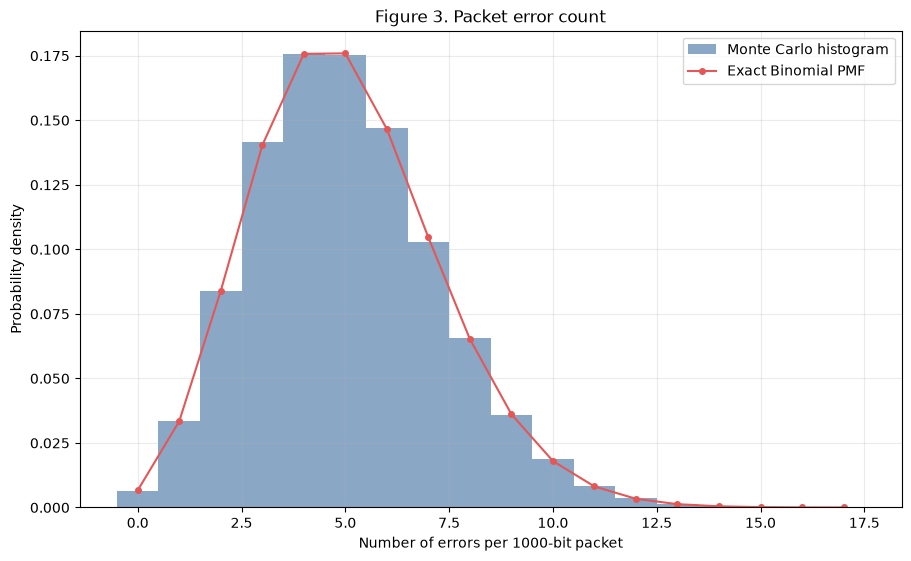

In [20]:
# Creating error count histogram 
max_error4 = errors4.max()
k4 = np.arange(0, max_error4 + 1)

fig3, ax3 = plt.subplots(figsize=(9, 5.5), constrained_layout=True)

ax3.hist(
    errors4,
    bins=np.arange(-0.5, max_error4 + 1.5, 1),
    density=True,
    alpha=0.65,
    color="#4c78a8",
    label="Monte Carlo histogram"
)

ax3.plot(
    k4,
    binom.pmf(k4, n_bits4, p4),
    "o-",
    color="#e45756",
    markersize=4,
    label="Exact Binomial PMF"
)

ax3.set_xlabel("Number of errors per 1000-bit packet")
ax3.set_ylabel("Probability density")
ax3.set_title("Figure 3. Packet error count")
ax3.legend()
ax3.grid(alpha=0.25)

plt.show()

In [23]:
# Comparing clean-packet probabilities
clean_p_values4 = [0.005, 0.001, 0.0001]
clean_rows4 = []

for p_clean4 in clean_p_values4:
    simulated_errors4 = packet_errors(
        n_pkt4,
        n_bits4,
        p_clean4,
        rng_step4
    )

    empirical_clean4 = np.mean(simulated_errors4 == 0)
    exact_clean4 = (1 - p_clean4) ** n_bits4
    difference_clean4 = empirical_clean4 - exact_clean4

    clean_rows4.append({
        "p": p_clean4,
        "Exact P(clean)": exact_clean4,
        "Empirical P(clean)": empirical_clean4,
        "Difference": difference_clean4
    })

clean_table4 = pd.DataFrame(clean_rows4)
print(clean_table4.to_string(index=False, float_format=lambda x: f"{x:.9f}"))

          p  Exact P(clean)  Empirical P(clean)   Difference
0.005000000     0.006653969         0.006040000 -0.000613969
0.001000000     0.367695425         0.368200000  0.000504575
0.000100000     0.904832894         0.905410000  0.000577106


## Step 4 Interpretation

The simulated histogram closely follows the exact Binomial PMF, confirming that the number of bit errors in each packet is well modeled by a Binomial distribution. The simulated mean and variance are close to the theoretical values,

$$
E[X] = np = 5
$$

and

$$
Var(X) = np(1-p) = 4.975.
$$

For \(p=0.005\), the probability that a 1000-bit packet is received without errors is approximately \(0.00657\), or \(0.657\%\). Thus, only a small fraction of packets arrive cleanly, meaning retransmissions would be very common at this bit-error rate. As the bit-error probability decreases, the probability of receiving a clean packet increases significantly.

## Step 5: Poisson Approximation

When $n$ is large and $p$ is small, a Binomial random variable can be approximated by a Poisson random variable with parameter $\lambda = np$.

The Binomial PMF is
$$
P(X=k)=\binom{n}{k}p^k(1-p)^{n-k},
$$

while the Poisson PMF is
$$
P(Y=k)=e^{-\lambda}\frac{\lambda^k}{k!}.
$$

The total variation distance measures the difference between two PMFs:
$$
d_{\mathrm{TV}}(P,Q) = \frac{1}{2}\sum_k |P(k)-Q(k)|.
$$

A value of zero means the distributions are identical. A value of one means they have completely disjoint support.


In [4]:
# Compute Binomial and Poisson Distributions
rng_step5 = rng_steps[4]  # Reserved for Step 5

n5 = 1000
p_values5 = [0.5, 0.05, 0.005, 0.001, 0.0005]
tail_tolerance5 = 1e-12


def common_pmfs5(n, p, tail_tolerance=1e-12):
    """Return a common support and truncated Binomial/Poisson PMFs."""
    lam = n * p

    # Select K so that the omitted Poisson upper tail is below tolerance.
    K = int(poisson.ppf(1 - tail_tolerance, lam))

    while poisson.sf(K, lam) >= tail_tolerance:
        K += 1

    k = np.arange(K + 1)

    binomial_pmf = binom.pmf(k, n, p)
    poisson_pmf = poisson.pmf(k, lam)
    poisson_tail = poisson.sf(K, lam)

    return k, binomial_pmf, poisson_pmf, poisson_tail


step5_rows = []
step5_results = {}

for p5 in p_values5:
    k5, binomial_pmf5, poisson_pmf5, poisson_tail5 = common_pmfs5(
        n5,
        p5,
        tail_tolerance5
    )

    distance5 = tv_distance(binomial_pmf5, poisson_pmf5)

    step5_results[p5] = {
        "k": k5,
        "binomial": binomial_pmf5,
        "poisson": poisson_pmf5,
        "tail": poisson_tail5,
        "tv": distance5
    }

    step5_rows.append({
        "p": p5,
        "lambda": n5 * p5,
        "TV distance": distance5,
        "Poisson tail": poisson_tail5
    })

step5_table = pd.DataFrame(step5_rows)

print(
    step5_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.6e}"
    )
)

           p       lambda  TV distance  Poisson tail
5.000000e-01 5.000000e+02 1.660573e-01  9.079137e-13
5.000000e-02 5.000000e+01 1.244598e-02  8.237578e-13
5.000000e-03 5.000000e+00 1.227570e-03  9.933985e-13
1.000000e-03 1.000000e+00 2.760706e-04  3.000011e-13
5.000000e-04 5.000000e-01 1.137711e-04  3.214697e-13


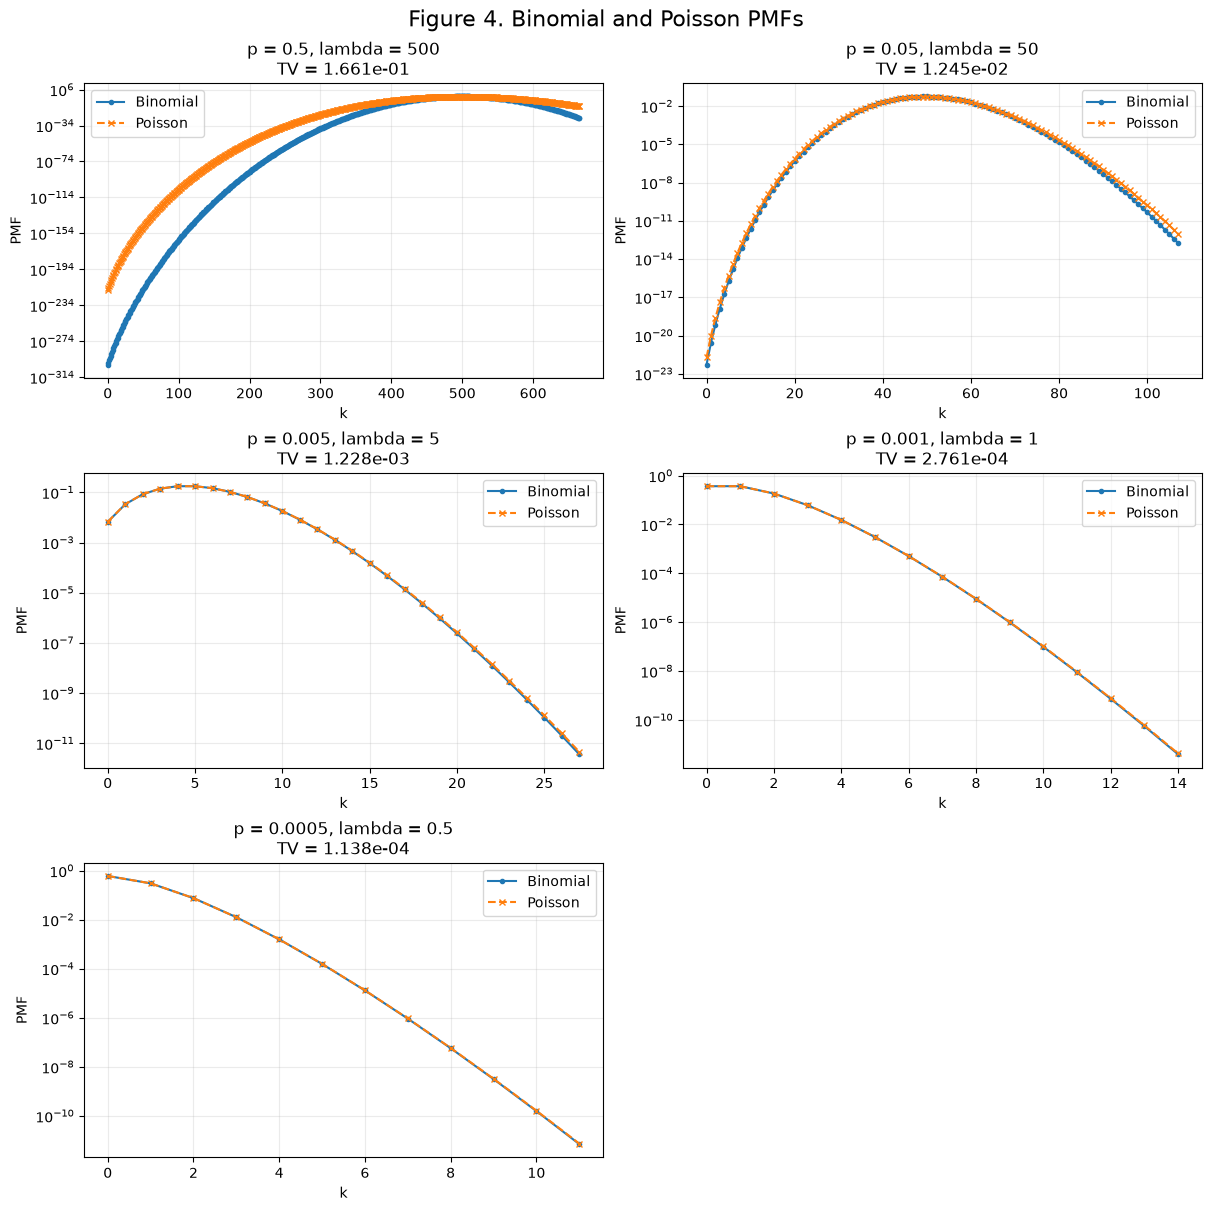

In [6]:
fig4, axes4 = plt.subplots(
    3,
    2,
    figsize=(12, 12),
    constrained_layout=True
)

axes4 = axes4.ravel()

for i, p5 in enumerate(p_values5):
    result5 = step5_results[p5]

    k5 = result5["k"]
    binomial_pmf5 = result5["binomial"]
    poisson_pmf5 = result5["poisson"]

    # Prevent zero values from causing issues on the log-scaled axis.
    binomial_plot5 = np.maximum(binomial_pmf5, 1e-300)
    poisson_plot5 = np.maximum(poisson_pmf5, 1e-300)

    axes4[i].plot(
        k5,
        binomial_plot5,
        "o-",
        markersize=3,
        label="Binomial"
    )

    axes4[i].plot(
        k5,
        poisson_plot5,
        "x--",
        markersize=4,
        label="Poisson"
    )

    axes4[i].set_yscale("log")
    axes4[i].set_xlabel("k")
    axes4[i].set_ylabel("PMF")
    axes4[i].set_title(
        f"p = {p5}, lambda = {n5 * p5:.3g}\n"
        f"TV = {result5['tv']:.3e}"
    )
    axes4[i].grid(alpha=0.25)
    axes4[i].legend()

# Hide the unused sixth subplot.
axes4[-1].axis("off")

fig4.suptitle(
    "Figure 4. Binomial and Poisson PMFs",
    fontsize=16
)

plt.show()

In [7]:
def tv_for_p5(p):
    """Calculate the TV distance for n=1000 and a selected p."""
    _, binomial_pmf, poisson_pmf, _ = common_pmfs5(
        n5,
        p,
        tail_tolerance5
    )
    return tv_distance(binomial_pmf, poisson_pmf)


# Verify that the distance generally increases with p.
p_check5 = np.linspace(0.001, 0.1, 100)
tv_check5 = np.array([tv_for_p5(p) for p in p_check5])

print("TV distance is increasing over the check grid:",
      np.all(np.diff(tv_check5) >= 0))

# Bisection for the largest p such that TV distance < 0.01.
p_low5 = 0.001
p_high5 = 0.1
tv_target5 = 0.01

while p_high5 - p_low5 > 1e-8:
    p_mid5 = 0.5 * (p_low5 + p_high5)

    if tv_for_p5(p_mid5) < tv_target5:
        p_low5 = p_mid5
    else:
        p_high5 = p_mid5

p_limit5 = p_low5
tv_limit5 = tv_for_p5(p_limit5)
le_cam_limit5 = n5 * p_limit5**2

print(f"Largest p with TV distance < 0.01: {p_limit5:.8f}")
print(f"TV distance at this p: {tv_limit5:.8f}")
print(f"Le Cam bound at this p: {le_cam_limit5:.8f}")
print(f"Le Cam threshold: {np.sqrt(0.01 / n5):.8f}")

TV distance is increasing over the check grid: True
Largest p with TV distance < 0.01: 0.04039359
TV distance at this p: 0.01000000
Le Cam bound at this p: 1.63164175
Le Cam threshold: 0.00316228


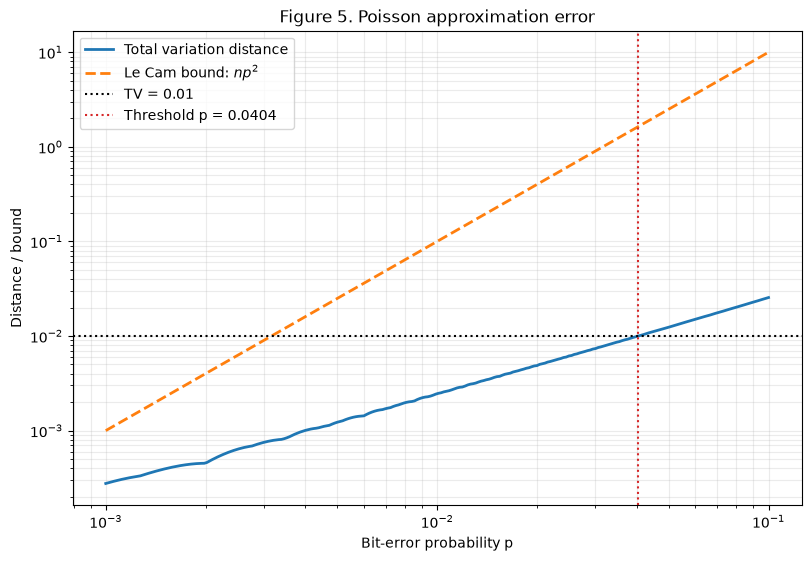

In [8]:
p_plot5 = np.logspace(np.log10(0.001), np.log10(0.1), 250)
tv_plot5 = np.array([tv_for_p5(p) for p in p_plot5])
le_cam_plot5 = n5 * p_plot5**2

fig5, ax5 = plt.subplots(figsize=(8, 5.5), constrained_layout=True)

ax5.loglog(
    p_plot5,
    tv_plot5,
    label="Total variation distance",
    linewidth=2
)

ax5.loglog(
    p_plot5,
    le_cam_plot5,
    "--",
    label=r"Le Cam bound: $np^2$",
    linewidth=2
)

ax5.axhline(
    0.01,
    color="black",
    linestyle=":",
    label="TV = 0.01"
)

ax5.axvline(
    p_limit5,
    color="tab:red",
    linestyle=":",
    label=f"Threshold p = {p_limit5:.4f}"
)

ax5.set_xlabel("Bit-error probability p")
ax5.set_ylabel("Distance / bound")
ax5.set_title("Figure 5. Poisson approximation error")
ax5.grid(True, which="both", alpha=0.25)
ax5.legend()

plt.show()

### Step 5 Interpretation

The Poisson approximation becomes more accurate as the bit-error probability $p$ decreases. This is shown by the decreasing total variation distance between the exact Binomial PMF and the Poisson PMF.

For $n=1000$, the Poisson approximation is most reliable when $p$ is small while the expected number of errors,
$$
\lambda=np,
$$
remains a reasonable event count. The total variation distance increases as $p$ increases, confirming that the approximation becomes less accurate for larger error probabilities.

The Le Cam bound,
$$
d_{\mathrm{TV}}\leq np^2,
$$
is conservative because it reaches $0.01$ at approximately
$$
p=\sqrt{\frac{0.01}{1000}}\approx 0.0032.
$$
The bisection result gives a larger value of $p$, meaning the Poisson approximation remains within the $0.01$ total variation threshold beyond the point predicted by the bound.


## Step 6: Retransmissions and the Geometric Distribution

Each transmission attempt is independent and has the same probability \(q\) of being received cleanly. Therefore, the number of attempts required until the first clean transmission follows a geometric distribution.

This implementation uses the convention

$$
X = 1, 2, 3, \ldots
$$

where \(X\) includes the successful attempt itself. Therefore,

$$
P(X = k) = (1-q)^{k-1}q
$$

$$
E[X] = \frac{1}{q}
$$

$$
\operatorname{Var}(X) = \frac{1-q}{q^2}
$$

NumPy's `rng.geometric(q)` uses this same convention: it returns the number of trials up to and including the first success. It does not return the number of failures before success.

In [2]:
# Step 6: Geometric retransmission behavior
rng_step6 = rng_steps[5]

q6 = 0.7
n_trials6 = 10**5

attempts6 = attempts_until_clean(
    n_trials6,
    q6,
    rng_step6
)

sample_mean6 = attempts6.mean()
sample_variance6 = attempts6.var(ddof=1)

theory_mean6 = 1 / q6
theory_variance6 = (1 - q6) / q6**2

print(f"Simulated trials: {n_trials6:,}")
print(f"Sample mean: {sample_mean6:.6f}")
print(f"Theoretical mean: {theory_mean6:.6f}")
print(f"Mean difference: {sample_mean6 - theory_mean6:+.6f}")
print()
print(f"Sample variance: {sample_variance6:.6f}")
print(f"Theoretical variance: {theory_variance6:.6f}")
print(f"Variance difference: {sample_variance6 - theory_variance6:+.6f}")

Simulated trials: 100,000
Sample mean: 1.432640
Theoretical mean: 1.428571
Mean difference: +0.004069

Sample variance: 0.623889
Theoretical variance: 0.612245
Variance difference: +0.011644


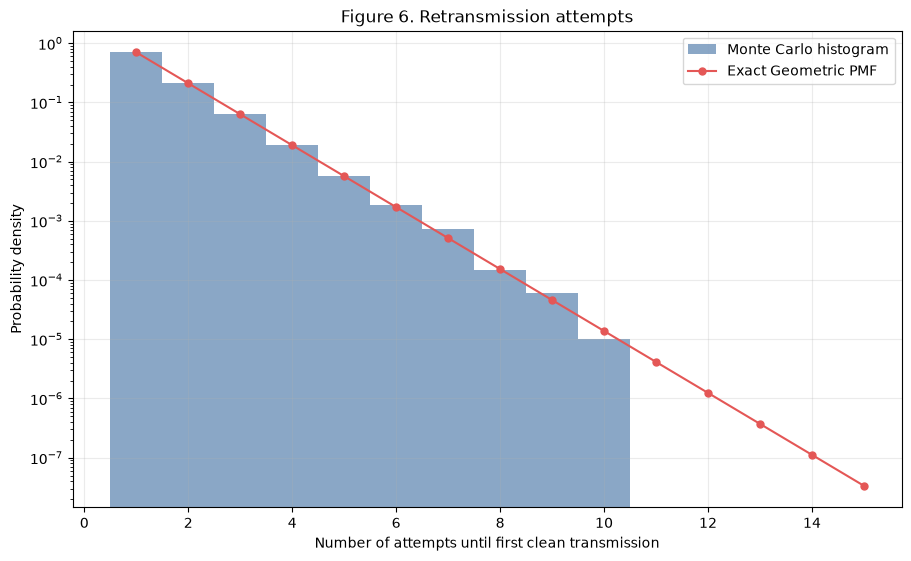

In [3]:
k6 = np.arange(1, max(attempts6.max(), 15) + 1)
geometric_pmf6 = geom.pmf(k6, q6)

fig6, ax6 = plt.subplots(
    figsize=(9, 5.5),
    constrained_layout=True
)

ax6.hist(
    attempts6,
    bins=np.arange(0.5, attempts6.max() + 1.5, 1),
    density=True,
    alpha=0.65,
    color="#4c78a8",
    label="Monte Carlo histogram"
)

ax6.plot(
    k6,
    np.maximum(geometric_pmf6, 1e-300),
    "o-",
    color="#e45756",
    markersize=5,
    label="Exact Geometric PMF"
)

ax6.set_yscale("log")
ax6.set_xlabel("Number of attempts until first clean transmission")
ax6.set_ylabel("Probability density")
ax6.set_title("Figure 6. Retransmission attempts")
ax6.grid(alpha=0.25)
ax6.legend()

plt.show()

In [4]:
memorylessness_pairs6 = [(1, 2), (3, 2), (5, 2)]
memorylessness_rows6 = []

for m6, n6 in memorylessness_pairs6:
    condition6 = attempts6 > m6
    event6 = attempts6 > (m6 + n6)

    # Estimate P(X > m+n | X > m)
    conditional_samples6 = event6[condition6]
    conditional_estimate6 = conditional_samples6.mean()
    conditional_count6 = len(conditional_samples6)

    # Estimate P(X > n)
    direct_samples6 = attempts6 > n6
    direct_estimate6 = direct_samples6.mean()

    theoretical_value6 = (1 - q6)**n6

    conditional_se6 = np.sqrt(
        conditional_estimate6
        * (1 - conditional_estimate6)
        / conditional_count6
    )

    direct_se6 = np.sqrt(
        direct_estimate6
        * (1 - direct_estimate6)
        / n_trials6
    )

    memorylessness_rows6.append({
        "m": m6,
        "n": n6,
        "Conditional estimate": conditional_estimate6,
        "Direct estimate": direct_estimate6,
        "Theoretical value": theoretical_value6,
        "Conditional difference": (
            conditional_estimate6 - theoretical_value6
        ),
        "Direct difference": (
            direct_estimate6 - theoretical_value6
        ),
        "Conditional SE": conditional_se6,
        "Direct SE": direct_se6
    })

memorylessness_table6 = pd.DataFrame(memorylessness_rows6)

print(
    memorylessness_table6.to_string(
        index=False,
        float_format=lambda x: f"{x:.8f}"
    )
)

 m  n  Conditional estimate  Direct estimate  Theoretical value  Conditional difference  Direct difference  Conditional SE  Direct SE
 1  2            0.09211965       0.09044000         0.09000000              0.00211965         0.00044000      0.00166443 0.00090698
 3  2            0.09996404       0.09044000         0.09000000              0.00996404         0.00044000      0.00568789 0.00090698
 5  2            0.07913669       0.09044000         0.09000000             -0.01086331         0.00044000      0.01619064 0.00090698


### Step 6 Interpretation

The simulated histogram closely follows the geometric PMF. The simulated mean and variance are also close to the theoretical values:

$$
E[X] = \frac{1}{q} = 1.4286
$$

$$
\operatorname{Var}(X) = \frac{1-q}{q^2} = 0.6122
$$

The memorylessness results show that

$$
P(X > m+n \mid X > m)
$$

is approximately equal to

$$
P(X > n) = (1-q)^n
$$

Therefore, previous failed attempts do not make the next attempt more likely to succeed. For example, five previous failures do not increase the success probability of the sixth attempt. Every attempt still has the same clean probability, \(q = 0.7\).

This memoryless behavior depends on the assumption that attempts are independent and have the same success probability. Real radio channels may violate this assumption because fading, interference, or other channel conditions can persist across multiple attempts.